# Proyecto 2 - Análisis Exploratorio
## CGIAR Eyes on the Ground Challenge

**Curso:** Data Science - UVG
**Integrante:** Osman
**Fecha:** Septiembre 2026

## 1. Investigación previa

El seguro agrícola basado en imágenes (*picture-based insurance*) usa fotos tomadas por agricultores para verificar reclamos, en vez de visitas físicas de un perito. El daño por sequía se identifica visualmente por marchitamiento, decoloración amarillenta/café y tamaño reducido de la planta. Hoy este proceso de verificación es manual, lo cual es lento y no escala bien ante muchos reclamos simultáneos.

## 2. Situación problemática, problema científico y objetivos

**Situación problemática:** la verificación manual de fotos de daño por sequía retrasa los pagos de seguro agrícola a pequeños agricultores en Kenia.

**Problema científico:** ¿qué patrones existen entre las imágenes, sus metadatos y el tipo/severidad de daño, que sirvan de base para automatizar la clasificación?

**Objetivos:**
- General: caracterizar el dataset para identificar qué distingue al daño por sequía de otros daños y de cultivos sanos.
- Específicos: (1) cuantificar la severidad del daño (`extent`) por temporada y etapa de crecimiento; (2) ver si la composición de tipos de daño cambia entre temporadas.

## 3. Carga y descripción de los datos

In [1]:
import pandas as pd
import numpy as np
from src.limpieza import cargar_train, resumen_nulos, filtrar_sequia, muestra_balanceada_por_clase
from src.descarga_imagenes import descargar_zip_si_no_existe, extraer_muestra
from src.visualizacion import histograma, boxplot_por_grupo, barras_frecuencia, grilla_imagenes

train = cargar_train("data/Train.csv")
test = pd.read_csv("data/Test.csv")

print(train.shape)
train.head()

(26068, 8)


,ID,filename,growth_stage,damage,extent,season,damage_label,growth_stage_label
0,ID_1S8OOWQYCB,L427F01330C01S03961Rp02052.jpg,S,WD,0,SR2020,Maleza,Siembra
1,ID_0MD959MIZ0,L1083F00930C39S12674Ip.jpg,V,G,0,SR2021,Bueno,Vegetativo
2,ID_JRJCI4Q11V,24_initial_1_1463_1463.JPG,V,G,0,LR2020,Bueno,Vegetativo
3,ID_DBO3ZGI1GM,L341F00167C01S00324Rp14178.jpg,M,DR,60,SR2020,Sequia,Madurez
4,ID_ORZLWTEUUS,L1084F02394C39S13931Ip.jpg,V,G,0,SR2021,Bueno,Vegetativo


In [2]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 26068 entries, 0 to 26067
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   ID                  26068 non-null  str  
 1   filename            26068 non-null  str  
 2   growth_stage        26068 non-null  str  
 3   damage              26068 non-null  str  
 4   extent              26068 non-null  int64
 5   season              26068 non-null  str  
 6   damage_label        26068 non-null  str  
 7   growth_stage_label  26068 non-null  str  
dtypes: int64(1), str(7)
memory usage: 1.6 MB


In [3]:
resumen_nulos(train)

Series([], dtype: int64)

In [4]:
# Comparación de tamaño train vs test
print(f"Train: {train.shape[0]} filas, {train.shape[1]} columnas")
print(f"Test:  {test.shape[0]} filas, {test.shape[1]} columnas")
print()
print("Columnas train:", train.columns.tolist())
print("Columnas test: ", test.columns.tolist())

Train: 26068 filas, 8 columnas
Test:  8663 filas, 5 columnas

Columnas train: ['ID', 'filename', 'growth_stage', 'damage', 'extent', 'season', 'damage_label', 'growth_stage_label']
Columnas test:  ['ID', 'filename', 'growth_stage', 'damage', 'season']


In [5]:
# Descripción formal de cada variable
descripcion_vars = pd.DataFrame({
    "variable": ["ID", "filename", "growth_stage", "damage", "extent", "season"],
    "tipo": ["identificador", "identificador", "categórica nominal", "categórica nominal", "numérica continua", "categórica nominal"],
    "descripcion": [
        "Identificador único del registro",
        "Nombre del archivo de imagen asociado",
        "Etapa de crecimiento del cultivo (S, V, F, M)",
        "Tipo de daño observado (DR, DS, FD, G, ND, PS, WD, WN)",
        "Porcentaje de severidad del daño (0-100), solo distinto de 0 cuando damage='DR'",
        "Temporada agrícola de la observación (ej. LR2020, SR2021)",
    ],
})
descripcion_vars

,variable,tipo,descripcion
0,ID,identificador,Identificador único del registro
1,filename,identificador,Nombre del archivo de imagen asociado
2,growth_stage,categórica nominal,"Etapa de crecimiento del cultivo (S, V, F, M)"
3,damage,categórica nominal,"Tipo de daño observado (DR, DS, FD, G, ND, PS,..."
4,extent,numérica continua,"Porcentaje de severidad del daño (0-100), solo..."
5,season,categórica nominal,Temporada agrícola de la observación (ej. LR20...


In [6]:
# Distribución (conteo y proporción) de cada variable categórica
for col in ["damage_label", "growth_stage_label", "season"]:
    print(f"--- {col} ---")
    tabla = train[col].value_counts().to_frame("conteo")
    tabla["proporcion_%"] = (tabla["conteo"] / len(train) * 100).round(2)
    print(tabla)
    print()

--- damage_label ---
                           conteo  proporcion_%
damage_label                                   
Bueno                       11623         44.59
Maleza                       9238         35.44
Sequia                       4516         17.32
Deficiencia de nutrientes     272          1.04
Plaga                         254          0.97
Enfermedad                    115          0.44
Viento                         37          0.14
Inundacion                     13          0.05

--- growth_stage_label ---
                    conteo  proporcion_%
growth_stage_label                      
Vegetativo           10015         38.42
Madurez               6664         25.56
Floracion             6164         23.65
Siembra               3225         12.37

--- season ---
        conteo  proporcion_%
season                      
SR2021    9927         38.08
LR2021    7945         30.48
SR2020    6163         23.64
LR2020    2033          7.80



`Train.csv`: 26,068 filas, 6 columnas (`ID`, `filename`, `growth_stage`, `damage`, `extent`, `season`), sin nulos. `Test.csv`: 8,663 filas, sin `extent`. `damage` está muy desbalanceado: Bueno (44.6%) y Maleza (35.4%) dominan; Sequía es 17.3% (4,516 casos); el resto suma <3%. `growth_stage` está más balanceado.

## 4. Limpieza y preprocesamiento

In [7]:
# Descarga del zip de imágenes de train (solo si no existe localmente)
descargar_zip_si_no_existe("train")

# Muestra balanceada por tipo de daño para inspección visual
muestra = muestra_balanceada_por_clase(train, columna="damage", n_por_clase=15)
extraer_muestra(muestra["filename"].tolist(), "train")

train.zip ya existe, no se vuelve a descargar.
Todas las imagenes de muestra de train ya estan extraidas.


'data/raw\\sample_images_train'

Sin nulos, no hubo imputación. `extent` solo es ≠0 para `damage='DR'` (decisión del dataset, no dato faltante), por lo que el EDA cuantitativo filtra solo esos registros. Para las imágenes (zips de 6.5GB/2.2GB en Drive), se descarga el zip una sola vez y se extrae solo una muestra balanceada por clase, sin descomprimir todo.

## 5. EDA cuantitativo — severidad del daño (extent)

In [8]:
# extent solo es informativo para damage == 'DR' (sequía)
sequia = filtrar_sequia(train)
sequia["extent"].describe()

count    4516.000000
mean       40.961027
std        24.754069
min         0.000000
25%        20.000000
50%        40.000000
75%        60.000000
max       100.000000
Name: extent, dtype: float64

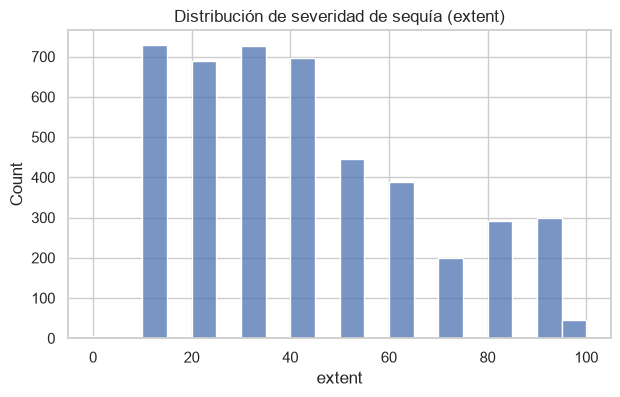

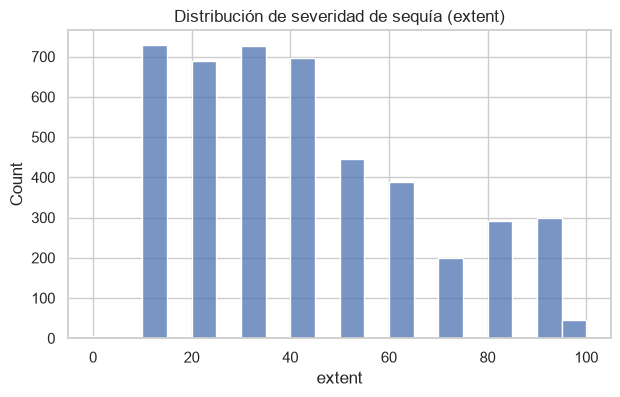

In [9]:
histograma(sequia, "extent", titulo="Distribución de severidad de sequía (extent)", nombre_archivo="hist_extent_sequia.png")

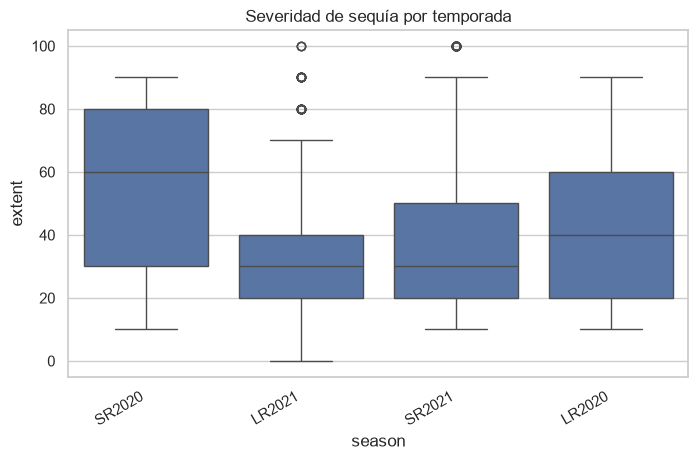

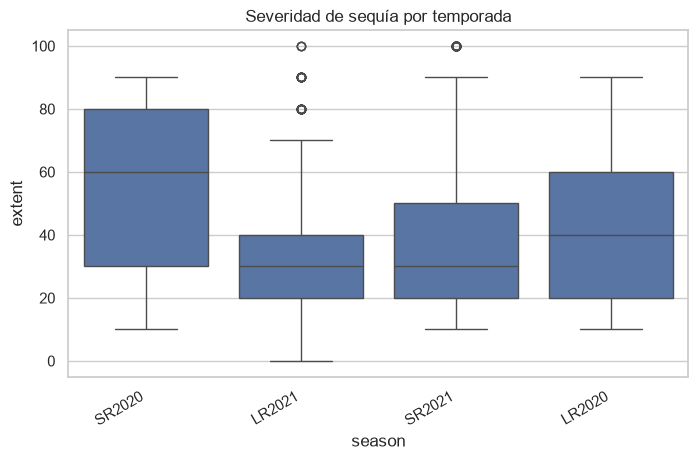

In [10]:
boxplot_por_grupo(sequia, "extent", "season", titulo="Severidad de sequía por temporada", nombre_archivo="box_extent_season.png")

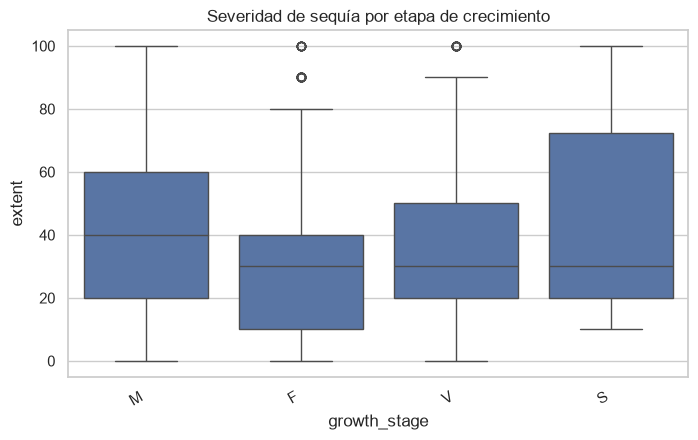

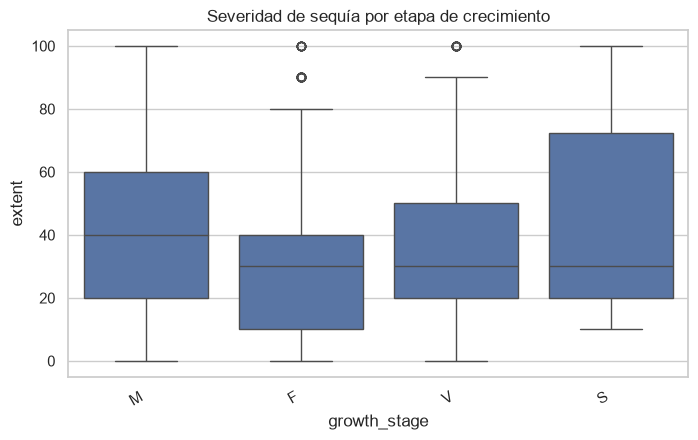

In [11]:
boxplot_por_grupo(sequia, "extent", "growth_stage", titulo="Severidad de sequía por etapa de crecimiento", nombre_archivo="box_extent_growth_stage.png")

In [12]:
# Detección de outliers en extent (sequía) usando el criterio de IQR
q1 = sequia["extent"].quantile(0.25)
q3 = sequia["extent"].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = sequia[(sequia["extent"] < limite_inferior) | (sequia["extent"] > limite_superior)]
print(f"Q1={q1}, Q3={q3}, IQR={iqr}")
print(f"Límites: [{limite_inferior}, {limite_superior}]")
print(f"Cantidad de outliers detectados: {len(outliers)} de {len(sequia)} ({len(outliers)/len(sequia)*100:.2f}%)")
outliers["extent"].value_counts().sort_index()

Q1=20.0, Q3=60.0, IQR=40.0
Límites: [-40.0, 120.0]
Cantidad de outliers detectados: 0 de 4516 (0.00%)


Series([], Name: count, dtype: int64)

In [13]:
# Estadística descriptiva de extent (sequía), agrupada por season y growth_stage
print("--- Por season ---")
print(sequia.groupby("season")["extent"].describe())
print()
print("--- Por growth_stage ---")
print(sequia.groupby("growth_stage")["extent"].describe())

--- Por season ---
         count       mean        std   min   25%   50%   75%    max
season                                                             
LR2020   391.0  43.145780  24.921965  10.0  20.0  40.0  60.0   90.0
LR2021  1413.0  34.501062  18.236199   0.0  20.0  30.0  40.0  100.0
SR2020  1146.0  53.516579  28.824544  10.0  30.0  60.0  80.0   90.0
SR2021  1566.0  37.056194  23.141861  10.0  20.0  30.0  50.0  100.0

--- Por growth_stage ---
               count       mean        std   min   25%   50%   75%    max
growth_stage                                                             
F              852.0  33.286385  22.707410   0.0  10.0  30.0  40.0  100.0
M             3238.0  43.350834  24.641661   0.0  20.0  40.0  60.0  100.0
S               20.0  46.000000  32.831307  10.0  20.0  30.0  72.5  100.0
V              406.0  37.758621  25.746166   0.0  20.0  30.0  50.0  100.0


La severidad de sequía tiene una media de 40.96% y mediana de 40%, con bastante dispersión (std 24.75) y valores en todo el rango 0-100%. Se ve que entre más alta la severidad, menos casos hay, los valores de 80-100% son los menos comunes. No salieron outliers a nivel global porque el IQR (40) es tan grande que los límites de Tukey quedan fuera del rango posible de la variable (-40, 120), así que la dispersión alta no significa que haya valores atípicos.

Por **temporada** sale el dato más interesante: aunque la frecuencia de sequía se mantenía parecida entre temporadas (~16-19%, visto antes en la parte categórica), la severidad sí cambia bastante, SR2020 es la más severa (53.5% de media) y LR2021 la menos severa (34.5%), casi la mitad. O sea que no es solo cuántos casos de sequía hay, sino qué tan fuerte es cada uno, y eso varía según la temporada.

Por **etapa de crecimiento**, Madurez tiene la severidad más alta (43.35%) y Floración la más baja (33.29%), lo cual llama la atención porque uno esperaría que floración fuera más vulnerable. (Ojo: la etapa S solo tiene 20 datos, así que no es muy confiable esa comparación).

Por grupo sí aparecen outliers que a nivel global no se ven: en LR2021 los valores de 80-100% salen como atípicos (su límite superior da 70), y lo mismo pasa en Floración (límite superior 85). Esto tiene sentido si se piensa que un valor "extremo" depende del contexto — es normal en SR2020, pero raro en LR2021 o Floración.

## 6. EDA categórico y visual

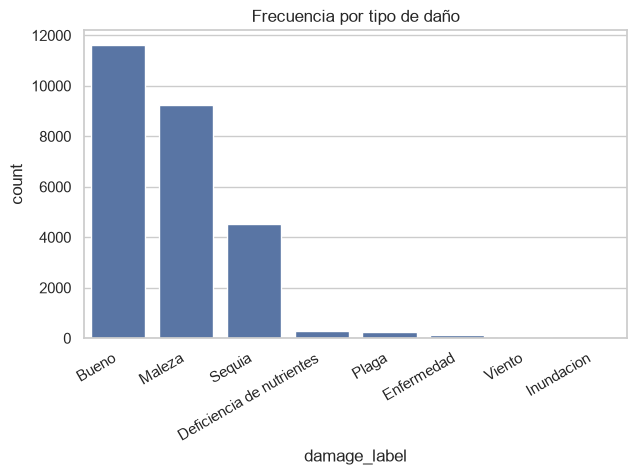

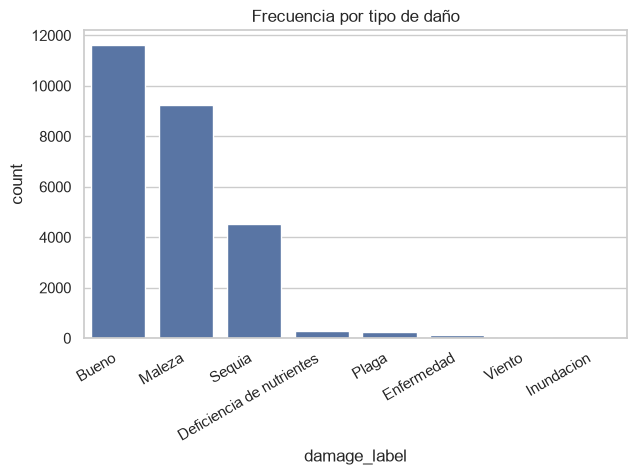

In [14]:
barras_frecuencia(train, "damage_label", titulo="Frecuencia por tipo de daño", nombre_archivo="barras_damage.png")

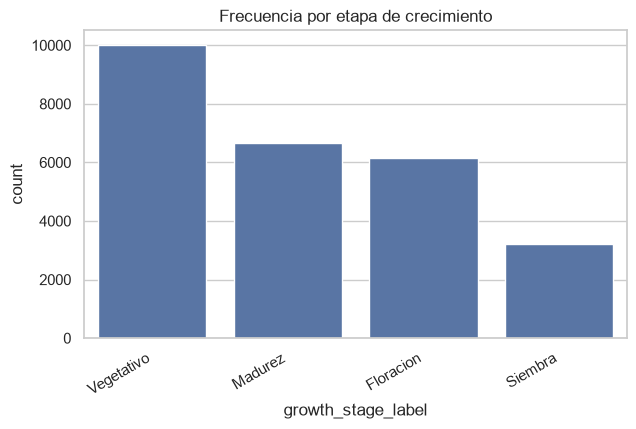

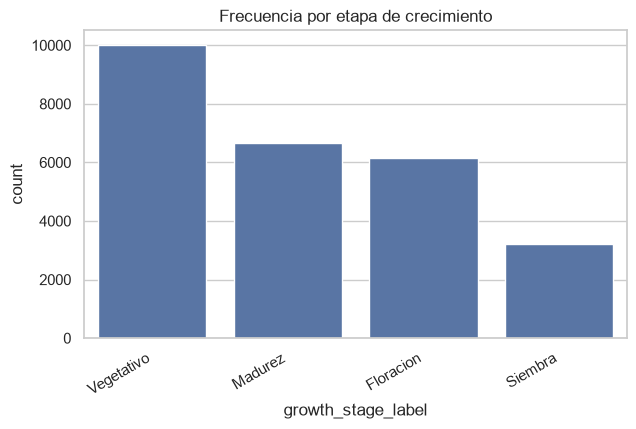

In [15]:
barras_frecuencia(train, "growth_stage_label", titulo="Frecuencia por etapa de crecimiento", nombre_archivo="barras_growth_stage.png")

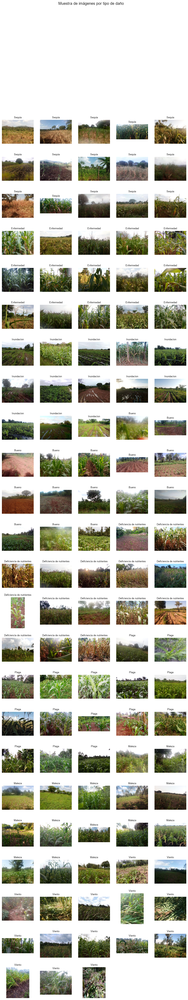

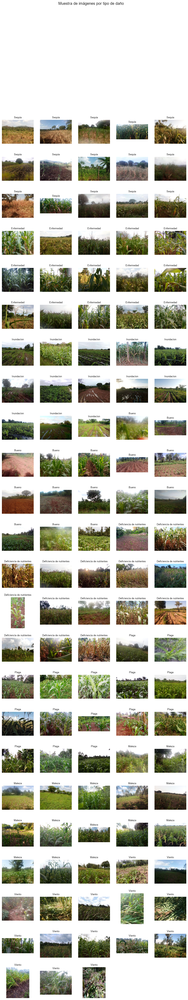

In [16]:
import os
rutas = [os.path.join("data/raw/sample_images_train", f) for f in muestra["filename"]]
etiquetas = muestra["damage_label"].tolist()
grilla_imagenes(rutas, etiquetas=etiquetas, cols=5, titulo="Muestra de imágenes por tipo de daño", nombre_archivo="grilla_muestra.png")

In [17]:
# Tabla cruzada: tipo de daño x temporada (conteos)
cruce_damage_season = pd.crosstab(train["damage_label"], train["season"])
cruce_damage_season

season,LR2020,LR2021,SR2020,SR2021
damage_label,,,,
Bueno,845,3468,2447,4863
Deficiencia de nutrientes,101,38,111,22
Enfermedad,72,22,10,11
Inundacion,0,3,0,10
Maleza,588,2938,2401,3311
Plaga,36,54,45,119
Sequia,391,1413,1146,1566
Viento,0,9,3,25


In [18]:
# Misma tabla, en proporciones por fila (para comparar composición de daño entre temporadas)
cruce_damage_season_pct = pd.crosstab(train["damage_label"], train["season"], normalize="columns") * 100
cruce_damage_season_pct.round(1)

season,LR2020,LR2021,SR2020,SR2021
damage_label,,,,
Bueno,41.6,43.7,39.7,49.0
Deficiencia de nutrientes,5.0,0.5,1.8,0.2
Enfermedad,3.5,0.3,0.2,0.1
Inundacion,0.0,0.0,0.0,0.1
Maleza,28.9,37.0,39.0,33.4
Plaga,1.8,0.7,0.7,1.2
Sequia,19.2,17.8,18.6,15.8
Viento,0.0,0.1,0.0,0.3


In [19]:
# Tabla cruzada: tipo de daño x etapa de crecimiento
cruce_damage_stage = pd.crosstab(train["damage_label"], train["growth_stage_label"])
cruce_damage_stage

growth_stage_label,Floracion,Madurez,Siembra,Vegetativo
damage_label,,,,
Bueno,3095,1659,2460,4409
Deficiencia de nutrientes,42,183,4,43
Enfermedad,48,58,1,8
Inundacion,1,1,5,6
Maleza,2057,1477,734,4970
Plaga,62,28,1,163
Sequia,852,3238,20,406
Viento,7,20,0,10


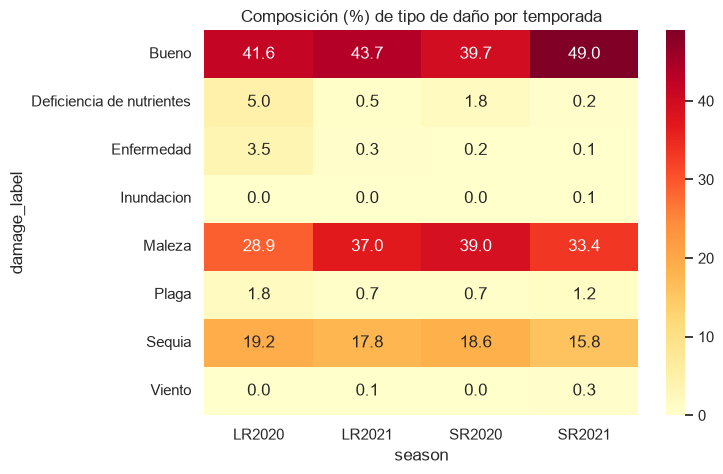

In [20]:
# Heatmap de la tabla cruzada damage x season (normalizada) para visualizar patrones
import matplotlib.pyplot as plt
import seaborn as sns
import os

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cruce_damage_season_pct, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax)
ax.set_title("Composición (%) de tipo de daño por temporada")
os.makedirs("figuras", exist_ok=True)
fig.savefig("figuras/heatmap_damage_season.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(tabla_cruzada):
    """Calcula Cramér's V a partir de una tabla de contingencia (conteos)."""
    chi2, p, dof, expected = chi2_contingency(tabla_cruzada)
    n = tabla_cruzada.sum().sum()
    k = min(tabla_cruzada.shape) - 1
    v = np.sqrt((chi2 / n) / k)
    return v, chi2, p

# Asociación entre daño y temporada
v_season, chi2_season, p_season = cramers_v(cruce_damage_season)
print(f"damage x season   -> Cramér's V = {v_season:.3f} | chi2 = {chi2_season:.1f} | p = {p_season:.4f}")

# Asociación entre daño y etapa de crecimiento
v_stage, chi2_stage, p_stage = cramers_v(cruce_damage_stage)
print(f"damage x growth_stage -> Cramér's V = {v_stage:.3f} | chi2 = {chi2_stage:.1f} | p = {p_stage:.4f}")

damage x season   -> Cramér's V = 0.120 | chi2 = 1130.0 | p = 0.0000
damage x growth_stage -> Cramér's V = 0.324 | chi2 = 8209.3 | p = 0.0000


En cuanto a frecuencia, Bueno domina con 44.6% (11,623), Maleza sigue con 35.4% (9,238), Sequía es 17.3% (4,516), y el resto de categorías juntas no llega al 3%. Por etapa de crecimiento, Vegetativo es la más común (38.4%), seguida de Madurez (25.6%), Floración (23.6%) y Siembra (12.4%).

Por temporada, la sequía se mantiene bastante estable (LR2020 19.2%, LR2021 17.8%, SR2020 18.6%, SR2021 15.8%) — las que más varían son Bueno y Maleza, así que otros factores (no la sequía) parecen explicar esos cambios entre temporadas.

El cruce más interesante es **daño por etapa de crecimiento**. Viendo qué % de cada etapa es sequía: Madurez 48.6%, Floración 13.9%, Vegetativo 4.1%, Siembra apenas 0.6% — mientras más avanzado el cultivo, más probable el daño por sequía. Y si se mira al revés, dónde se concentran los casos de sequía: Madurez agrupa el 71.7% de todos ellos. Esto conecta directo con lo visto en la sección anterior, donde Madurez también tenía la severidad promedio más alta (43.35%) y Floración la más baja (33.29%) — o sea que Madurez es donde la sequía ocurre más seguido *y* donde pega más fuerte.

Para confirmar esto con un número, se calculó Cramér's V (medida de asociación para variables categóricas): entre `damage` y `season` da 0.120 (asociación débil), mientras que entre `damage` y `growth_stage` da 0.324 (moderada, casi el triple). Esto respalda numéricamente lo que ya se veía en las tablas: la etapa de crecimiento explica bastante más el tipo de daño que la temporada.

Por último, la grilla de imágenes confirma la diferencia visual esperada (tonos café/amarillentos y plantas marchitas en sequía vs. verde uniforme en Bueno/Maleza), aunque hay bastante variación de ángulo y encuadre entre fotos de una misma clase, lo que podría meter ruido si esto se usara para un modelo de clasificación.

## 7. Hallazgos y conclusiones



El análisis confirma que la sequía es un fenómeno relativamente estable en frecuencia entre temporadas (~16-19% de los casos), pero altamente variable en severidad — SR2020 registró la sequía más intensa (media 53.5%) mientras que LR2021 la más leve (34.5%). Esto responde directamente al objetivo específico de ver si la severidad cambia entre temporadas: sí cambia, y bastante, aunque la frecuencia no lo refleje.

El hallazgo más fuerte del análisis es la relación entre sequía y etapa de crecimiento: Madurez concentra el 71.7% de todos los casos de sequía del dataset, y dentro de esa etapa casi la mitad de las observaciones (48.6%) son sequía. Además, Madurez es también la etapa con mayor severidad promedio (43.35%), mientras que Floración tiene tanto la menor frecuencia (13.9%) como la menor severidad (33.29%). Frecuencia y severidad apuntan en la misma dirección, lo que sugiere que el riesgo real de sequía se concentra fuertemente en la etapa de madurez del cultivo.

Visualmente, las clases de daño sí se distinguen (tonos café/amarillentos y plantas marchitas en sequía vs. verde uniforme en Bueno/Maleza), pero la falta de estandarización en el ángulo y encuadre de las fotos es una limitación a tener en cuenta — podría afectar el desempeño de un futuro modelo de clasificación basado solo en imagen.

Otra limitación importante es el desbalance de clases: Bueno y Maleza concentran el 80% de los datos, mientras que categorías como Inundación o Viento tienen menos de 40 casos cada una. Esto no afecta el análisis exploratorio en sí, pero sería un problema a resolver (por ejemplo con sobremuestreo o pesos de clase) si en el futuro se entrenara un modelo de clasificación con estos datos.

En cuanto al problema científico planteado, los patrones encontrados —sobre todo la fuerte asociación entre madurez del cultivo y daño por sequía— sí sientan una base útil para pensar en automatizar la verificación de reclamos: priorizar la revisión automática de fotos tomadas en etapas de madurez podría ser un punto de partida razonable para un futuro modelo.